In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
import xgboost as xgb
from xgboost import XGBClassifier

In [103]:
aqs = pd.read_csv('C:/Users/mayav/Desktop/GEOL415/LA_AQS_2023.csv')

In [104]:
O3_aqs = aqs[(aqs['Parameter Name']=='Ozone')]
NO2_aqs = aqs[(aqs['Parameter Name']=='Nitrogen dioxide (NO2)')]
O3 = pd.DataFrame(data = {"O3" : (O3_aqs['Arithmetic Mean']* 1e3), 'Time' : (O3_aqs['Date (Local)'])})
NO2 = pd.DataFrame(data = {"NO2" : (NO2_aqs['Arithmetic Mean']), 'Time' : (NO2_aqs['Date (Local)'])})
O3andNO2 = O3.merge(NO2, on=['Time'])

In [105]:
axVal = np.array(O3andNO2['O3']).reshape((-1, 1))
ayVal = np.array(O3andNO2['NO2'])
aqsmodel = linear_model.LinearRegression()
aqsmodel.fit(axVal,ayVal)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.46]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.56
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[368.64]


In [106]:
waves = pd.read_csv('waves_2023.txt', sep=r'\s+')

In [107]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE','YY','MM','DD','hh','mm'], axis=1) 
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [108]:
df_X = waves.drop(['WVHT'],axis=1).to_numpy() 
df_y = waves['WVHT'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [109]:
wavesxgb = xgb.XGBRegressor(n_estimators=25)
wavesxgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [110]:
from sklearn.ensemble import RandomForestRegressor
wavesregRF = RandomForestRegressor(n_estimators=100)
wavesregRF = wavesregRF.fit(X_train, y_train)
yPred = wavesregRF.predict(X_val)

In [111]:
from sklearn.tree import DecisionTreeRegressor

wavesdtr = DecisionTreeRegressor()
wavesdtr = wavesdtr.fit(X_train, y_train)
dtryPred = wavesdtr.predict(X_val)

In [115]:
waveslinear = linear_model.LinearRegression()
waveslinear.fit(df_X,df_y)
rYPred= waveslinear.predict(X_val)

In [116]:
from sklearn.inspection import permutation_importance

In [121]:
metric = 'neg_root_mean_squared_error'
r = permutation_importance(wavesxgb, X_test, y_test, n_repeats=30, scoring=metric, random_state=42)
features = waves.columns
sorted_imp_idx = r.importances_mean.argsort()

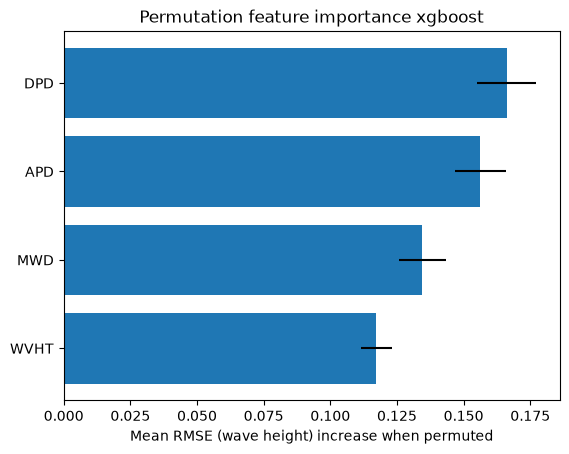

In [122]:
plt.barh(range(len(r.importances_mean)), r.importances_mean[sorted_imp_idx], xerr = r.importances_std[sorted_imp_idx]         )
plt.yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
plt.title('Permutation feature importance xgboost')
plt.xlabel('Mean RMSE (wave height) increase when permuted')
plt.show()

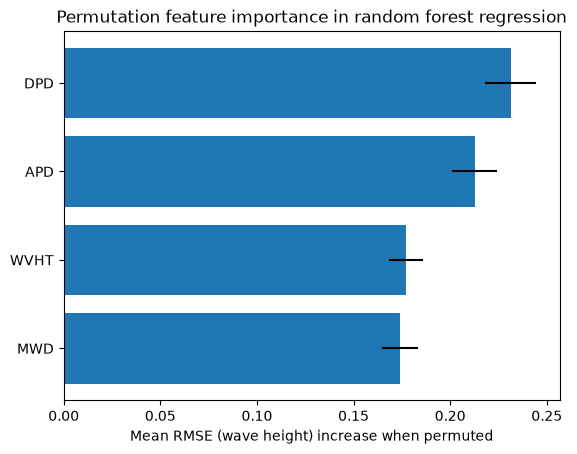

In [128]:
k = permutation_importance(wavesregRF, X_test, y_test, n_repeats=30, scoring=metric, random_state=42)
features = waves.columns
ksorted_imp_idx = k.importances_mean.argsort()
plt.barh(range(len(k.importances_mean)), k.importances_mean[ksorted_imp_idx], xerr = k.importances_std[ksorted_imp_idx])
plt.yticks(range(len(k.importances_mean)), features[ksorted_imp_idx])
plt.title('Permutation feature importance in random forest regression')
plt.xlabel('Mean RMSE (wave height) increase when permuted')
plt.show()

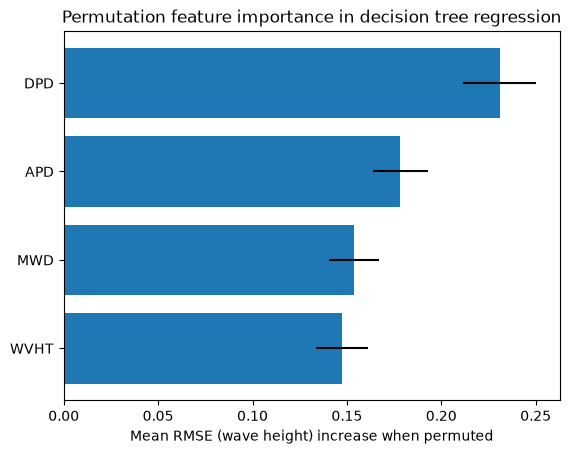

In [129]:
j = permutation_importance(wavesdtr, X_test, y_test, n_repeats=30, scoring=metric, random_state=42)
features = waves.columns
jsorted_imp_idx = j.importances_mean.argsort()
plt.barh(range(len(j.importances_mean)), j.importances_mean[jsorted_imp_idx], xerr = j.importances_std[jsorted_imp_idx])
plt.yticks(range(len(j.importances_mean)), features[jsorted_imp_idx])
plt.title('Permutation feature importance in decision tree regression')
plt.xlabel('Mean RMSE (wave height) increase when permuted')
plt.show()

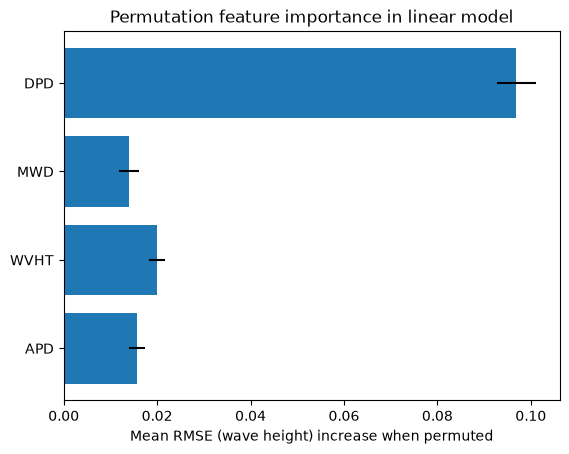

In [131]:
n = permutation_importance(waveslinear, X_test, y_test, n_repeats=30, scoring=metric, random_state=42)
features = waves.columns
nsorted_imp_idx = n.importances_mean.argsort()
plt.barh(range(len(n.importances_mean)), n.importances_mean[jsorted_imp_idx], xerr = n.importances_std[nsorted_imp_idx])
plt.yticks(range(len(n.importances_mean)), features[nsorted_imp_idx])
plt.title('Permutation feature importance in linear model')
plt.xlabel('Mean RMSE (wave height) increase when permuted')
plt.show()

In [123]:
m = permutation_importance(aqsmodel, axVal, ayVal, n_repeats=30, scoring=metric, random_state=42)
features = O3andNO2.columns
wsorted_imp_idx = m.importances_mean.argsort()

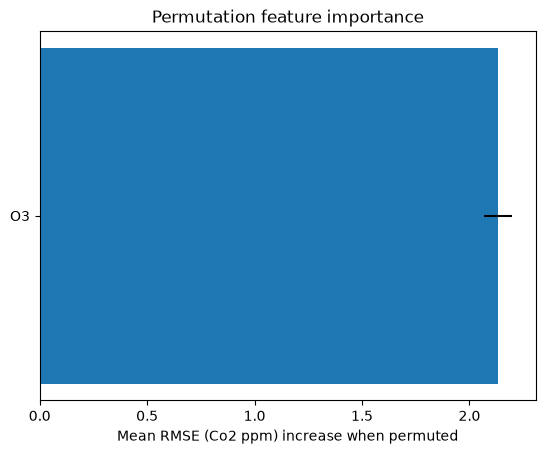

In [124]:
plt.barh(range(len(m.importances_mean)), m.importances_mean[wsorted_imp_idx], xerr = m.importances_std[wsorted_imp_idx])
plt.yticks(range(len(m.importances_mean)), features[wsorted_imp_idx])
plt.title('Permutation feature importance')
plt.xlabel('Mean RMSE (Co2 ppm) increase when permuted')
plt.show()